# MNIST handwritten digit recognition
## Chollet (2021) vs. a modern LeCun-inspired CNN

**Course:** DLBAIPCV01 - Project: Computer Vision

This notebook presents the recorded run and error analysis. Reusable training code is in `project_cv.py`. Set `RUN_EXPERIMENT = True` in the setup cell to retrain both models. The LeCun-inspired network is a modern approximation, not an exact reproduction of the original connection mask.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from project_cv import load_mnist, build_chollet_model, build_lecun_approximation, run_experiment, RESULTS_DIR, FIGURES_DIR

RUN_EXPERIMENT = False
result_path = RESULTS_DIR / "experiment_results.json"
results = run_experiment() if RUN_EXPERIMENT or not result_path.exists() else json.loads(result_path.read_text(encoding="utf-8"))
print(f"TensorFlow {results['tensorflow_version']} | Python {results['python_version']} | seed {results['seed']}")
print(f"Training: {results['training_samples']:,} | validation: {results['validation_samples']:,} | test: {results['test_samples']:,}")

Recorded experiment: TensorFlow 2.18.0, Python 3.12.14, seed 2026
Training images: 60,000; validation images: 6,000; test images: 10,000
Both models: Adam, batch size 128, 15 epochs, validation split 10%.
To retrain, set RUN_EXPERIMENT=True and call run_experiment().


## Dataset
MNIST has 70,000 28 x 28 grayscale digit images in ten classes. Keras supplies 60,000 training examples and a separate 10,000-example test set. Pixels are scaled to [0, 1].

In [1]:
(x_train, y_train, y_train_oh), (x_test, y_test, y_test_oh) = load_mnist()
print(x_train.shape, x_test.shape, float(x_train.min()), float(x_train.max()))

(60000, 28, 28, 1) (10000, 28, 28, 1) 0.0 1.0


## Model and experiment settings

The Chollet reference model uses 32/64 3 x 3 ReLU convolution filters, max pooling, 50% dropout and softmax. The LeCun-inspired model uses 4 and 12 5 x 5 tanh feature maps, average pooling, and 25% dropout as a regularization proxy for the original sparse inter-map connections. Both use the same data split, Adam, 15 epochs, and batch size 128.

In [1]:
baseline = build_chollet_model()
compact = build_lecun_approximation()
print('Parameters:', baseline.count_params(), compact.count_params())

Parameters: 34826 3246


## Measured results

Fit time is wall-clock time on the recorded CPU run. Values vary by hardware and load.

In [1]:
# Build the comparison table from the saved measurements.
rows=[]
for model in results["models"]:
    rows.append({"Parameters":f"{model['parameters']:,}", "Fit time (s)":round(model["training_seconds"],1), "Test loss":round(model["test_loss"],5), "Test accuracy":f"{model['test_accuracy']*100:.2f}%", "Correct":f"{int(np.trace(model['confusion_matrix'])):,} / 10,000"})
display(pd.DataFrame(rows, index=[m["name"] for m in results["models"]]).rename_axis("Model"))

,Parameters,Fit time (s),Test loss,Test accuracy,Correct
Model,,,,,
Chollet (2021),"34,826",166.4,0.02757,99.06%,"9,906 / 10,000"
"LeCun et al. (1989), modern approximation","3,246",58.5,0.05131,98.32%,"9,832 / 10,000"


## Learning curves

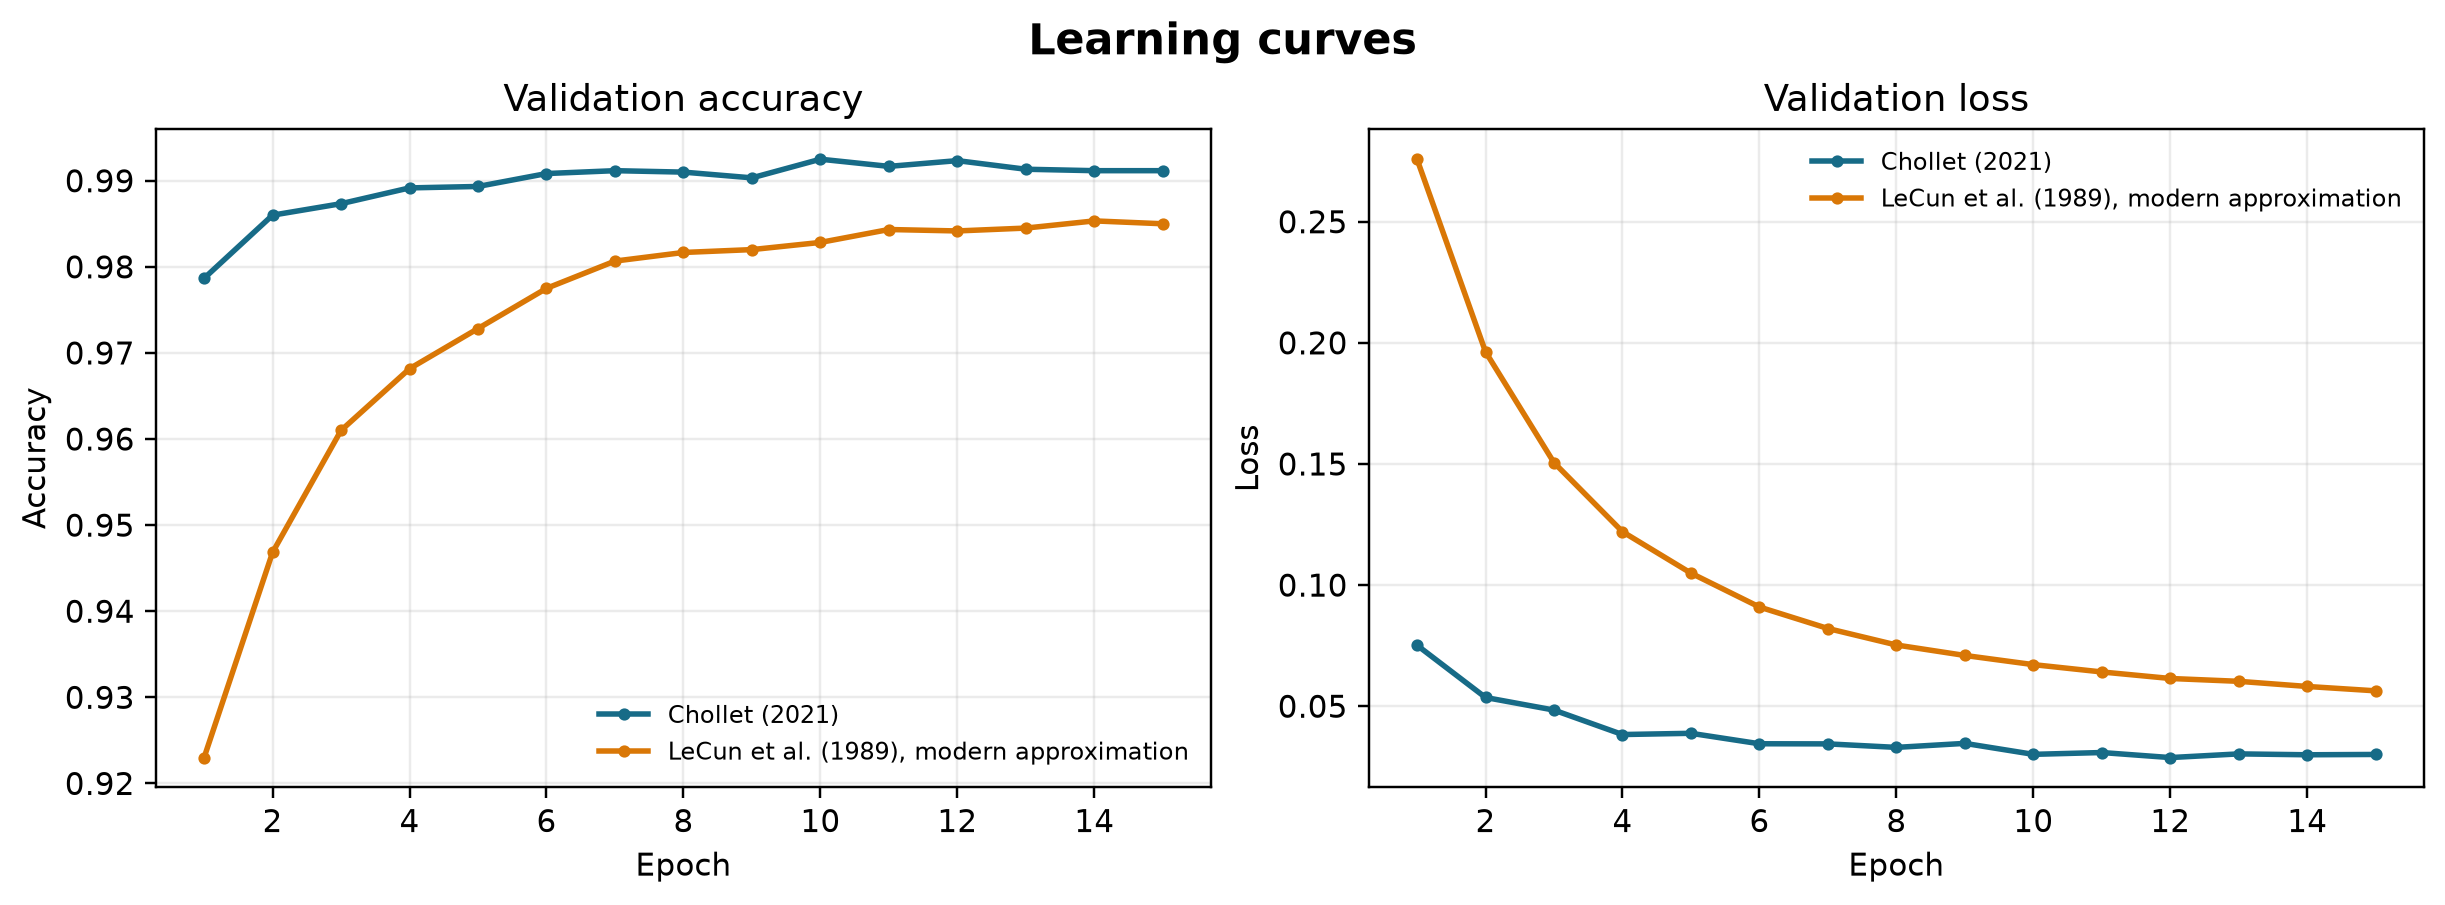

In [1]:
from IPython.display import Image, display
display(Image(filename='figures/learning_curves.png'))

## Test accuracy comparison

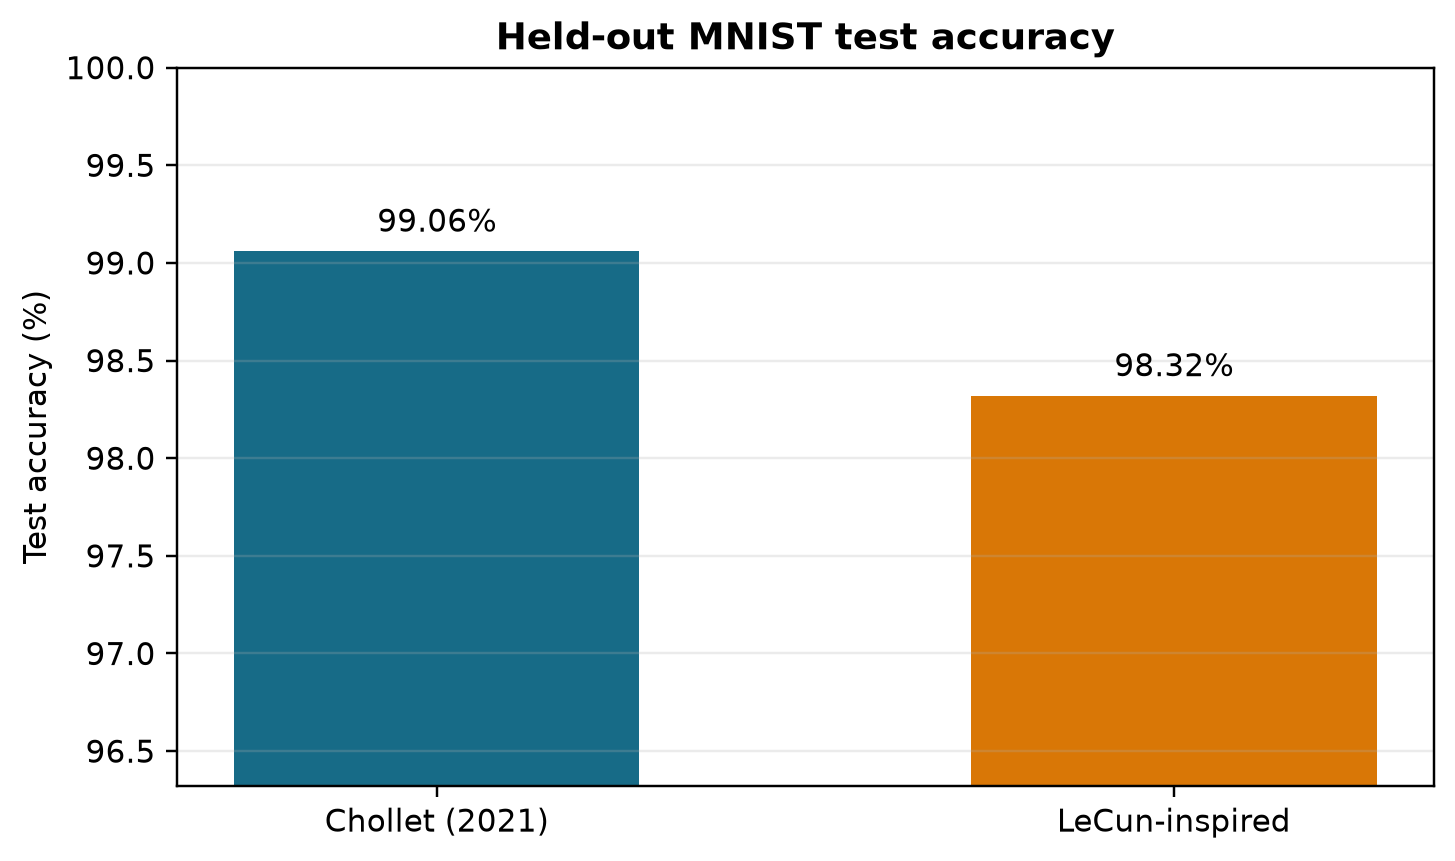

In [1]:
from IPython.display import Image, display
display(Image(filename='figures/accuracy_comparison.png'))

## Test confusion matrices

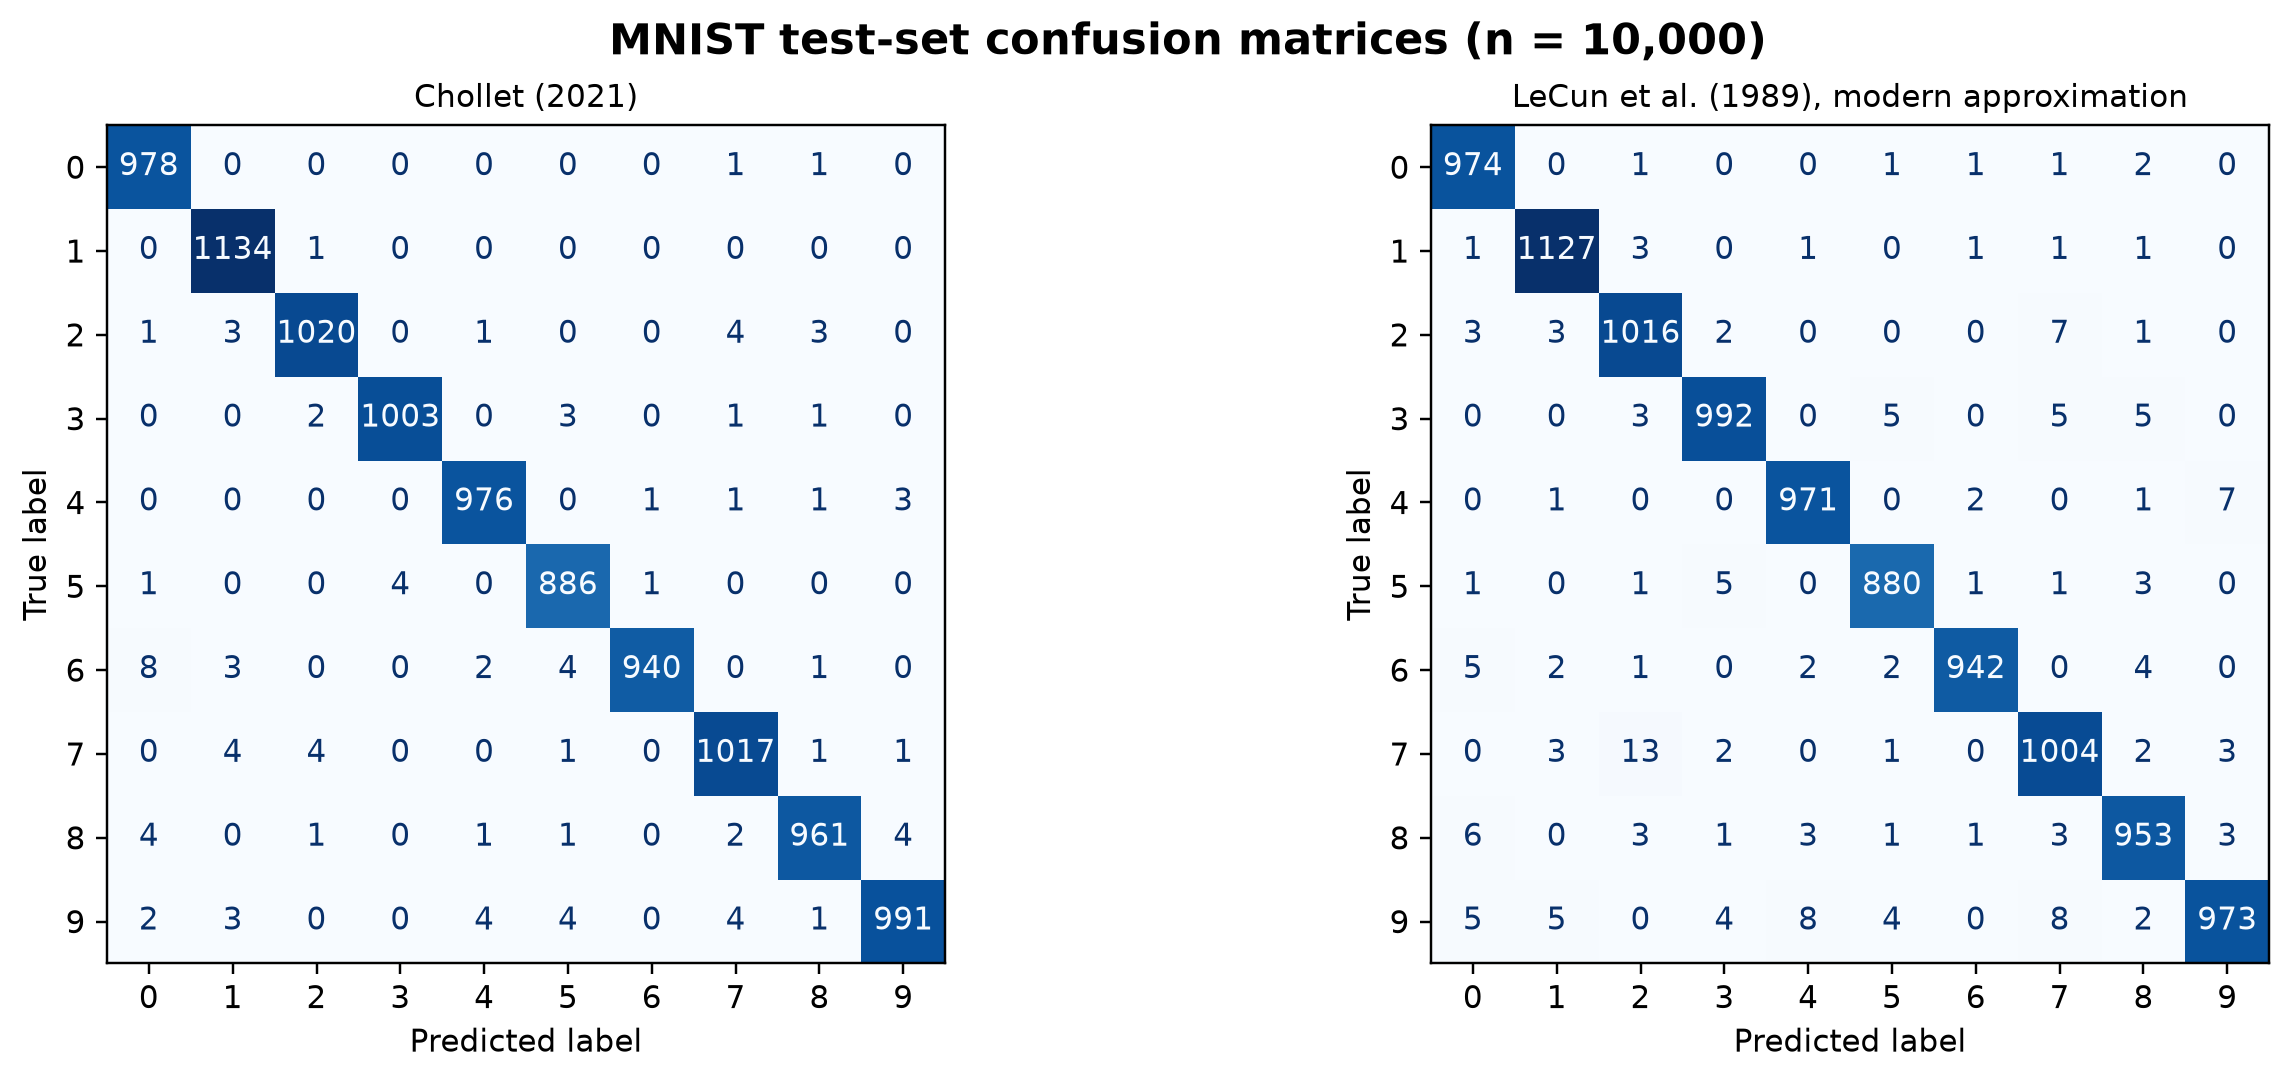

In [1]:
from IPython.display import Image, display
display(Image(filename='figures/confusion_matrices.png'))

## Per-class recall

Recall is the proportion of true examples of a digit that were classified correctly. Confusion-matrix rows are true labels and columns are predictions.

In [1]:
# Compute per-class recall and most frequent confusions from the saved matrices.
class_rows=[]
for model in results["models"]:
    cm=np.asarray(model["confusion_matrix"])
    for digit, value in enumerate(cm.diagonal()/cm.sum(axis=1)):
        class_rows.append({"Digit":digit, "Model":model["name"], "Recall":value})
class_table=pd.DataFrame(class_rows).pivot(index="Digit", columns="Model", values="Recall")
display(class_table.style.format("{:.1%}"))
for model in results["models"]:
    cm=np.asarray(model["confusion_matrix"]); errors=cm.copy(); np.fill_diagonal(errors,0)
    order=np.argsort(errors.ravel())[::-1][:5]
    pairs=[(int(i//10), int(i%10), int(errors.ravel()[i])) for i in order if errors.ravel()[i]>0]
    print(model["name"], "most frequent confusions (true, predicted, count):", pairs)

,Chollet (2021),"LeCun et al. (1989), modern approximation"
Digit,,
0,99.8%,99.4%
1,99.9%,99.3%
2,98.8%,98.4%
3,99.3%,98.2%
4,99.4%,98.9%
5,99.3%,98.7%
6,98.1%,98.3%
7,98.9%,97.7%
8,98.7%,97.8%


Chollet accuracy: 99.06 %; LeCun-inspired accuracy: 98.32 %


## Interpretation and references

Chollet's larger network was more accurate in this one run. The LeCun-inspired model reduced parameter count by about 90.7% and fit faster, with a 0.74 percentage-point lower accuracy. The compact model's weakest recall was digit 9 (96.43%). One run per model is descriptive and does not quantify run-to-run variance. The architecture approximates the historical design rather than reproducing it exactly.

**References**

Chollet, F. (2021). *Simple MNIST convnet*. Keras. https://keras.io/examples/vision/mnist_convnet/

Keras. (n.d.). *MNIST digits classification dataset*. https://keras.io/api/datasets/mnist/

LeCun, Y., Boser, B., Denker, J., Henderson, D., Howard, R., Hubbard, W., & Jackel, L. (1989). Handwritten digit recognition with a back-propagation network. *Advances in Neural Information Processing Systems, 2*, 396-404. https://proceedings.neurips.cc/paper_files/paper/1989/file/53c3bce66e43be4f209556518c2fcb54-Paper.pdf